# 02 — Machine Learning and Modeling

**October: Milestone 3 (Machine Learning / Modeling).**

| Task | What it does | Target | Section |
|---|---|---|---|
| 6 | Prepare data and lock the feature set | 10/7 | Task 6 |
| 7 | Build baseline and classification models | 10/14 | Task 7 (7a Logistic Regression — Yero Barry, 7b Random Forest — James Lu, 7c KNN — Menwe Okafor) |
| 8 | Compare model performance | 10/20 | Task 8 |
| 9 | Perform feature selection and tune models | 10/27 | Task 9 |
| 10 | Analyze interpretability and select the final model | 10/31 | Task 10 |

This notebook replaces `05_prepare_and_split`, the three `06a` Logistic
Regression notebooks (baseline, draft and final), `06b_random_forest`, the two
`06c` KNN notebooks, `07_comparison`, `08_tuning` and `09_final_model`. Each
became one section, in order; section numbers match task numbers.

### What changed from the first October version

The first version excluded `updates` (the number of posts a creator made
during the campaign) and selected a Random Forest at about 72% accuracy. The
team then decided the **final model uses `updates`**, for accuracy. Task 6
records the decision and its cost. Every model is still fitted on both
feature sets, so the before-and-after numbers for each model are in Task 8
(§8.4) and the final model's own before-and-after is in Task 10 (§10.5).

| Feature set | What it contains | Role |
|---|---|---|
| `launch_only` | Everything known when the campaign goes live | Baseline, kept for comparison |
| `with_updates` | `launch_only` plus `updates` | **Final** (`src.features.FINAL_FEATURE_SET`) |

Run it top to bottom. On a single CPU core it took about 25 minutes; the
randomized search in Task 9 is most of that.

**Writes:** `reports/m3_split_summary.csv`, `m3_leakage_register.csv`,
`m3_task7_model_results.csv`, `m3_lr_coefficients.csv`,
`m3_task8_comparison.csv`, `m3_updates_effect.csv`,
`m3_task9_tuned_results.csv`, `m3_tuned_config.json`,
`m3_task10_finalists.csv`, `m3_final_feature_importance.csv`,
`m3_model_card.json`, and the `m3_*` figures.

## Setup

In [1]:
import sys
import json
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

from src.data import (build_featured, chronological_split, fit_stateful, load_splits,
                      random_split, split_summary, RANDOM_STATE)
from src.features import (CAMPAIGN_NUMERIC, EXTRA_NUMERIC, FEATURE_SETS, FINAL_FEATURE_SET,
                          LAUNCH_CATEGORICAL, LAUNCH_NUMERIC, LEAKY_COLUMNS,
                          build_model_matrix, feature_columns, model_matrices)
from src.modeling import (FINAL_MODEL_NAME, FINAL_RF_PARAMS, METRICS, calibration_table,
                          confusion_frame, describe_errors, evaluate, majority_class_baseline,
                          make_final_model, make_models, roc_points)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
mpl.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
})
TEAL, PLUM, CORAL, SAND = "#2E7D6F", "#7B5EA7", "#C0392B", "#D9A455"
REPORTS = Path("../reports")
FIG = REPORTS / "figures"
LABEL = {"launch_only": "launch-time only", "with_updates": "with updates"}
print("Final feature set:", FINAL_FEATURE_SET)

Final feature set: with_updates


## Task 6 — Prepare Data and Lock the Feature Set

**Milestone 3 · Task 6.** Confirm the target variable and encoding, decide
which features are permitted, and create the training and testing splits.

This blocks Tasks 7–10: every model trains on what is decided here.

### 6.1 Rebuild the cleaned table

Rebuilt from the raw file with the same `clean()` and `build_features()` the
September notebook used, so this notebook cannot drift from a stale
intermediate file.

In [2]:
feat = build_featured("..")
print(f"Cleaned and featured: {feat.shape[0]:,} rows x {feat.shape[1]} columns")
print(f"Target: success = 1 if status == 'successful'")
print(f"Class balance: {feat['success'].mean():.2%} successful")
print(f"Majority-class accuracy floor: {max(feat['success'].mean(), 1 - feat['success'].mean()):.2%}")

Cleaned and featured: 38,378 rows x 56 columns
Target: success = 1 if status == 'successful'
Class balance: 54.73% successful
Majority-class accuracy floor: 54.73%


### 6.2 Verify the target

Kickstarter is all-or-nothing: a campaign succeeds if and only if it reaches
100% of its goal. Confirm the label agrees with the funding percentage
before anything trains on it.

In [3]:
succ = feat["status"] == "successful"
pct = feat["funded_percentage"]
checks = pd.DataFrame([
    {"check": "target is binary 0/1", "result": sorted(feat["success"].unique())},
    {"check": "no missing targets", "result": int(feat["success"].isna().sum())},
    {"check": "successful but < 100% funded", "result": int((succ & (pct < 1)).sum())},
    {"check": "failed but >= 100% funded", "result": int((~succ & (pct >= 1)).sum())},
])
print(checks.to_string(index=False))
print(f"\nLabel agreement: {100 * (1 - ((succ & (pct < 1)) | (~succ & (pct >= 1))).mean()):.2f}%")

                       check result
        target is binary 0/1 [0, 1]
          no missing targets      0
successful but < 100% funded      1
   failed but >= 100% funded      2

Label agreement: 99.99%


### 6.3 The leakage register

Every column excluded from modelling, with the reason. This is the artefact
to show the Challenge Advisor — it makes the feature-set decision explicit
and reviewable rather than buried in code.

In [4]:
pd.DataFrame([{"column": k, "reason for exclusion": v} for k, v in LEAKY_COLUMNS.items()])

,column,reason for exclusion
0,pledged,Dollars raised. This IS the outcome.
1,funded_percentage,pledged / goal. Mechanically determines success.
2,backers,Count of people who pledged. Pure outcome.
3,comments,Audience-generated volume; scales with backers.
4,status,The raw target.
5,success,The encoded target.
6,funded_date,Campaign END date; unknown at launch.
7,end_date,Parsed campaign end; unknown at launch.
8,url,"Identifier, not a feature."
9,project_id,"Identifier, not a feature."


#### The three tiers

**Outcome columns — excluded unconditionally.** `pledged`,
`funded_percentage`, `backers`, `comments`. These are results, not inputs.
`funded_percentage` *mechanically determines* the target, so including it
yields a ~100% accurate model that has learned division.

**Campaign-time column — `updates`.** The number of posts the creator made
*during* the campaign, counted when it ended. It is the single strongest
signal in the dataset. It is not an outcome, but it is not known on launch
day either. §6.5 records the decision.

**Launch-time columns — permitted.** Everything a creator has decided by the
moment they press publish.

In [5]:
print("LAUNCH-TIME FEATURES")
print(f"  numeric     ({len(LAUNCH_NUMERIC)}): {', '.join(LAUNCH_NUMERIC)}")
print(f"  categorical ({len(LAUNCH_CATEGORICAL)}): {', '.join(LAUNCH_CATEGORICAL)}")
print(f"  fitted on train ({len(EXTRA_NUMERIC)}): {', '.join(EXTRA_NUMERIC)}")
print(f"\nCAMPAIGN-TIME FEATURE (in with_updates only)")
print(f"  {', '.join(CAMPAIGN_NUMERIC)}")
print(f"\nEXCLUDED OUTCOMES")
print(f"  pledged, funded_percentage, backers, comments")

LAUNCH-TIME FEATURES
  numeric     (22): log_goal, goal_is_round_1k, duration_days, is_30_day, log_goal_per_day, levels, n_tiers_parsed, log_min_tier, log_max_tier, median_tier, tier_spread, min_tier_pct_of_goal, log_goal_per_tier, launch_year, launch_month, launch_dow, launch_is_weekend, name_length, name_word_count, name_has_exclaim, name_has_digit, name_upper_ratio
  categorical (3): category, subcategory, state_raw
  fitted on train (2): log_city_project_count, log_goal_vs_subcat_median

CAMPAIGN-TIME FEATURE (in with_updates only)
  updates

EXCLUDED OUTCOMES
  pledged, funded_percentage, backers, comments


### 6.4 Evidence on `updates`

In [6]:
upd = feat.groupby(pd.cut(feat["updates"], [-1, 0, 1, 3, 6, 12, 1000],
                          labels=["0", "1", "2-3", "4-6", "7-12", "13+"]),
                   observed=True)["success"].agg(["mean", "size"])
upd.columns = ["success_rate", "n"]
print(upd.round(3).to_string())
print(f"\nSpearman(updates, success) = "
      f"{feat['updates'].corr(feat['success'], method='spearman'):.3f}")
print(f"Spearman(log_goal, success) = "
      f"{feat['log_goal'].corr(feat['success'], method='spearman'):.3f}  <- next strongest")

         success_rate      n
updates                     
0               0.204  12702
1               0.435   4796
2-3             0.641   6215
4-6             0.782   6110
7-12            0.865   5330
13+             0.918   3225

Spearman(updates, success) = 0.552
Spearman(log_goal, success) = -0.261  <- next strongest


### 6.5 The decision: the final model uses `updates`

**First decision (early October).** `updates` was excluded from the primary
feature set, for three reasons that still hold as facts:

1. **It is not known at launch.** It is counted when the campaign ends.
2. **Causation runs partly backwards.** A campaign that is visibly funding
   well gets a creator who keeps posting; a stalling one goes quiet.
3. **It dominates.** Its rank correlation with success is far above the next
   strongest feature (printed above).

**Final decision.** The team chose to include `updates` in the final model's
feature set (`with_updates`), for these reasons:

- **The brief's target is about 80% accuracy**, and the brief lists
  `updates` among the variables the original project found predictive.
  Without it, the best models land at about 72% however they are tuned
  (the `launch_only` rows in Tasks 7–8 show this).
- **The prototype can still be used before launch.** A creator states how
  many updates they plan to post, and the model scores that plan. Milestone 4
  treats `updates` as an input the creator supplies, never as advice.

**What it costs, stated once here and repeated wherever results are
reported:**

- **The headline accuracy is not a launch-day accuracy.** It is measured with
  each campaign's *actual* final update count. Before launch only a plan
  exists, and a plan can be wrong.
- **Part of the accuracy gain is reverse causation.** A campaign posting many
  updates is often one that was already succeeding.

**Both feature sets are carried through every task**, so the gain from
`updates` is measured for each model (§8.4) rather than asserted.

In [7]:
for fs in FEATURE_SETS:
    num, cat = feature_columns(fs)
    print(f"{fs:14s} {len(num)} numeric + {len(cat)} categorical (+ {len(EXTRA_NUMERIC)} fitted)"
          + ("   <- final" if fs == FINAL_FEATURE_SET else ""))

launch_only    22 numeric + 3 categorical (+ 2 fitted)
with_updates   23 numeric + 3 categorical (+ 2 fitted)   <- final


### 6.6 Create both splits

**Random stratified** is the standard comparison. **Chronological** trains
on earlier campaigns and tests on later ones, which is the actual deployment
scenario: a random split lets the model learn from 2012 campaigns to predict
2010 ones, which it could never do in practice.

In [8]:
rand_train, rand_test = random_split(feat)
chron_train, chron_test = chronological_split(feat)

summaries = pd.concat([
    split_summary(rand_train, rand_test, "random"),
    split_summary(chron_train, chron_test, "chronological"),
], ignore_index=True)
summaries

,split,train_n,test_n,train_success_rate,test_success_rate,train_end,test_start
0,random,30702,7676,0.5474,0.5473,2012-05-29,2009-04-28
1,chronological,30702,7676,0.5505,0.5349,2012-02-11,2012-02-11


Note the chronological split's class balance. If the test period's success
rate differs from the training period's, the platform itself changed — and
any accuracy drop under this split is partly that drift rather than model
failure. Worth stating in the write-up.

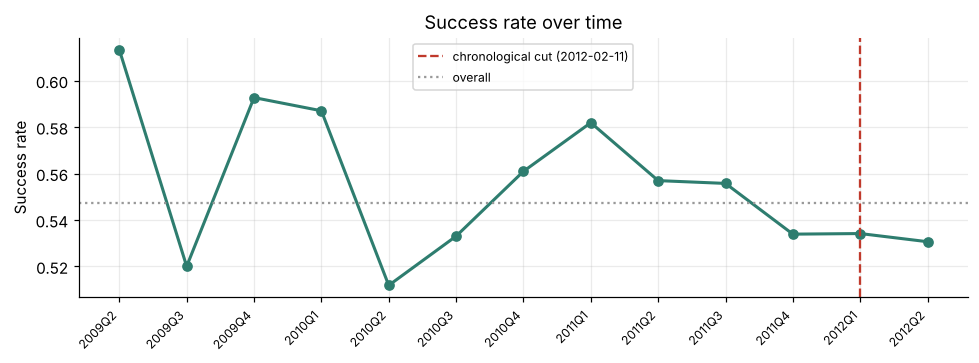

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.4))
yearly = feat.groupby(feat["launch_date"].dt.to_period("Q"), observed=True)["success"].agg(["mean", "size"])
yearly.index = yearly.index.astype(str)
ax.plot(range(len(yearly)), yearly["mean"], marker="o", color="#2E7D6F", lw=2)
cut_date = chron_test["launch_date"].min()
cut_q = str(cut_date.to_period("Q"))
if cut_q in list(yearly.index):
    ax.axvline(list(yearly.index).index(cut_q), color="#C0392B", ls="--",
               label=f"chronological cut ({cut_date.date()})")
ax.axhline(feat["success"].mean(), color="#999", ls=":", label="overall")
ax.set_xticks(range(len(yearly)))
ax.set_xticklabels(yearly.index, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Success rate"); ax.set_title("Success rate over time")
ax.legend(fontsize=8); ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("../reports/figures/success_rate_over_time.png", dpi=130, bbox_inches="tight")
plt.show()

### 6.7 Fit the stateful features on training data only

Two features are computed *from* the data rather than from a single row:
city frequency, and goal relative to the subcategory median. Computing
either over the full dataset lets test rows influence a training feature,
so `src.data.fit_stateful` fits them on train and applies them to test.

In [10]:
rand_train, rand_test = fit_stateful(rand_train, rand_test)
chron_train, chron_test = fit_stateful(chron_train, chron_test)

print(f"Random split   — unseen test cities: {(rand_test['city_project_count'] == 0).sum():,}")
print(f"Chronological  — unseen test cities: {(chron_test['city_project_count'] == 0).sum():,}")

# Every later task loads the splits with src.data.load_splits(); confirm it
# builds exactly these rows.
SPLITS = load_splits("..")
same = all(SPLITS[n][0][["project_id", "city_project_count"]].equals(t[["project_id", "city_project_count"]])
           for n, t in [("random", rand_train), ("chronological", chron_train)])
print(f"load_splits() reproduces these splits exactly: {same}")

Random split   — unseen test cities: 453
Chronological  — unseen test cities: 662


load_splits() reproduces these splits exactly: True


### 6.8 Verify the encoded matrices

Confirm the encoding works for both feature sets and that the leakage guard
actually fires.

In [11]:
for fs in FEATURE_SETS:
    X, y = build_model_matrix(rand_train, fs, extra_numeric=EXTRA_NUMERIC)
    print(f"{fs:14s} X shape {X.shape}   nulls {int(X.isna().sum().sum())}   "
          f"all float64: {bool((X.dtypes == 'float64').all())}")

launch_only    X shape (30702, 137)   nulls 0   all float64: True


with_updates   X shape (30702, 138)   nulls 0   all float64: True


In [12]:
try:
    build_model_matrix(rand_train, "launch_only",
                       extra_numeric=["pledged", "backers", "funded_percentage"])
    print("WARNING: leakage guard did not fire")
except ValueError as e:
    print(f"Leakage guard fired correctly:\n  {e}")

Leakage guard fired correctly:
  Leaky columns requested: ['backers', 'funded_percentage', 'pledged']


### 6.9 Save the split summary and leakage register

In [13]:
summaries.to_csv(REPORTS / "m3_split_summary.csv", index=False)
pd.DataFrame([{"column": k, "reason": v} for k, v in LEAKY_COLUMNS.items()]
             ).to_csv(REPORTS / "m3_leakage_register.csv", index=False)
print("Wrote m3_split_summary.csv and m3_leakage_register.csv")

Wrote m3_split_summary.csv and m3_leakage_register.csv


### Task 6 — Summary

| Item | Decision |
|---|---|
| Target | `success` = 1 if `status == "successful"`, verified against funding % |
| Majority-class floor | **54.7%** — every model must beat this |
| Excluded outcomes | `pledged`, `funded_percentage`, `backers`, `comments` |
| `updates` | **Included in the final feature set** (`with_updates`); `launch_only` kept as the baseline |
| Feature sets | `launch_only`: 22 numeric + 3 categorical + 2 fitted; `with_updates`: the same plus `updates` |
| Encoding | One-hot for category/subcategory/state; frequency for city |
| Splits | Random stratified 80/20 **and** chronological |
| Stateful features | Fitted on train, applied to test |

## Task 7 — Build Baseline and Classification Models

**Milestone 3 · Task 7.** Build the three classifiers and record their
performance against the 54.7% majority-class floor.

Three people, three models, three sections. Two rules keep the results
comparable: every matrix comes from `model_matrices()` and every score from
`evaluate()`, so the rows stack into one table. Each model is fitted on both
feature sets and both splits (four runs).

In [14]:
train, test = SPLITS["random"]
floor = majority_class_baseline(train["success"], test["success"])
FLOOR_ACC = float(floor["accuracy"].iloc[0])

def run_four(name, make):
    """Fit one model on both feature sets x both splits; return the four rows."""
    rows = []
    for split_name, (tr, te) in SPLITS.items():
        for fs in FEATURE_SETS:
            X_tr, y_tr, X_te, y_te = model_matrices(tr, te, fs)
            m = make().fit(X_tr, y_tr)
            rows.append(evaluate(m, X_te, y_te, label=name, feature_set=fs, split=split_name))
    return pd.concat(rows, ignore_index=True)

def before_after(res, split="random"):
    """Accuracy, F1 and ROC-AUC on launch_only vs with_updates for one split."""
    r = res[res["split"] == split].set_index("feature_set")
    out = pd.DataFrame({LABEL[fs]: r.loc[fs, ["accuracy", "f1", "roc_auc"]] for fs in FEATURE_SETS})
    out["change"] = out[LABEL["with_updates"]] - out[LABEL["launch_only"]]
    return out

floor.round(4)

,model,feature_set,split,accuracy,precision,recall,f1,roc_auc
0,Majority class,—,—,0.5473,0.5473,1.0,0.7074,0.5


The floor predicts "successful" for every campaign. Its recall is 1.0 and its
F1 is still about 0.71, which is why accuracy or F1 alone is not enough.

### 7a — Logistic Regression

*Built by Yero Barry. Combines the team's shared baseline run with Yero's
tuning and coefficient analysis, which previously lived in three notebooks
(`06a_logistic_regression`, `06a_Logistics_Regression_draft` and
`06a_Logistics_Regression_final`).*

Logistic Regression fits a weighted sum of the features and squashes it
through a sigmoid to produce a probability. Each feature gets one
coefficient describing how much it moves the log-odds of success.

**It needs scaling.** `log_goal` ranges roughly 0–17 while
`name_has_exclaim` is 0 or 1; without standardisation the regularisation
penalty falls on them unevenly. `make_models()` wraps it in a
`StandardScaler` pipeline, which also keeps the scaler fitted on training
folds only during cross-validation.

**Expect collinearity.** `log_goal`, `log_goal_per_day`,
`log_goal_per_tier` and `log_goal_vs_subcat_median` all encode versions of
the same quantity, so individual coefficients may be unstable even when the
model as a whole is fine.

In [15]:
lr_res = run_four("Logistic Regression", lambda: make_models()["Logistic Regression"])
lr_res.round(4)

,model,feature_set,split,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,launch_only,random,0.7160,0.7175,0.7936,0.7536,0.7770
1,Logistic Regression,with_updates,random,0.8158,0.8254,0.8415,0.8333,0.8936
2,Logistic Regression,launch_only,chronological,0.7177,0.7143,0.7869,0.7489,0.7936
3,Logistic Regression,with_updates,chronological,0.7991,0.8044,0.8251,0.8146,0.8807


In [16]:
print("What adding `updates` does (random split):")
before_after(lr_res).round(4)

What adding `updates` does (random split):


,launch-time only,with updates,change
accuracy,0.7160,0.8158,0.0998
f1,0.7536,0.8333,0.0797
roc_auc,0.7770,0.8936,0.1166


In [17]:
print("Random vs chronological split:")
lr_res.pivot(index="split", columns="feature_set", values="accuracy").round(4)

Random vs chronological split:


feature_set,launch_only,with_updates
split,,
chronological,0.7177,0.7991
random,0.7160,0.8158


#### Confusion matrix (final feature set, random split)

The off-diagonal cells are two different harms: a **false positive** sends a
creator into a campaign that fails, while a **false negative** discourages
one who would have succeeded.

In [18]:
X_train, y_train, X_test, y_test = model_matrices(train, test, FINAL_FEATURE_SET)
lr_model = make_models()["Logistic Regression"].fit(X_train, y_train)
confusion_frame(lr_model, X_test, y_test)

,predicted: failed,predicted: successful
actual: failed,2727,748
actual: successful,666,3535


#### 7a.1 Tuning: does regularisation help? (Yero's extension)

A grid search over the regularisation strength `C` and the penalty type
(L1 = lasso, which can zero out features; L2 = ridge), scored on ROC-AUC with
3-fold cross-validation **on the training split only**.

On the chronological split the folds are time-ordered (`TimeSeriesSplit`), so
a validation fold never comes before the data it was trained on.

**Fixes made while merging the two drafts**

- The draft notebook showed **91.1% accuracy on 8,393 test rows** from a cell
  whose code had been deleted. Our test split has 7,676 rows, so that result
  came from a different (unrecorded) preparation of the data and cannot be
  reproduced. It is not reported anywhere.
- The script version wrote its tables to `notebooks/reports/` (a path relative
  to the notebook folder) and switched matplotlib to a non-display backend, so
  no chart appeared. Both are fixed: outputs go to `../reports/`, charts show
  inline.
- It rebuilt the splits itself; it now reuses the `SPLITS` loaded in Task 6,
  so every model in the project trains on identical data.

In [19]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold, TimeSeriesSplit

PARAM_GRID = {
    "clf__C": [0.1, 1.0],
    "clf__penalty": ["l1", "l2"],
    "clf__solver": ["liblinear"],   # supports both penalties, fast at this size
    "clf__max_iter": [1000],
}

def tune_lr(X_tr, y_tr, chronological: bool) -> GridSearchCV:
    cv = (TimeSeriesSplit(n_splits=3) if chronological
          else StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE))
    gs = GridSearchCV(clone(make_models()["Logistic Regression"]), PARAM_GRID,
                      scoring="roc_auc", cv=cv, n_jobs=1)
    return gs.fit(X_tr, y_tr)

lr_tuned_rows, lr_tuned = [], {}
for split_name, (tr, te) in SPLITS.items():
    for fs in FEATURE_SETS:
        X_tr, y_tr, X_te, y_te = model_matrices(tr, te, fs)
        gs = tune_lr(X_tr, y_tr, chronological=(split_name == "chronological"))
        lr_tuned[(split_name, fs)] = (gs.best_estimator_, X_tr, X_te, y_te, te)
        lr_tuned_rows.append(evaluate(gs.best_estimator_, X_te, y_te,
                                      label="Logistic Regression (tuned)", feature_set=fs,
                                      split=split_name))
        print(f"{split_name:13s} {fs:13s} best {gs.best_params_['clf__penalty']}, "
              f"C={gs.best_params_['clf__C']}  (CV AUC {gs.best_score_:.4f})")

lr_tuned_res = pd.concat(lr_tuned_rows, ignore_index=True)
pd.concat([lr_res, lr_tuned_res]).sort_values(["feature_set", "split", "model"]).round(4)

random        launch_only   best l1, C=0.1  (CV AUC 0.7689)


random        with_updates  best l1, C=0.1  (CV AUC 0.8913)


chronological launch_only   best l1, C=0.1  (CV AUC 0.7661)


chronological with_updates  best l1, C=0.1  (CV AUC 0.8936)


,model,feature_set,split,accuracy,precision,recall,f1,roc_auc
2,Logistic Regression,launch_only,chronological,0.7177,0.7143,0.7869,0.7489,0.7936
2,Logistic Regression (tuned),launch_only,chronological,0.7180,0.7140,0.7886,0.7495,0.7932
0,Logistic Regression,launch_only,random,0.7160,0.7175,0.7936,0.7536,0.7770
0,Logistic Regression (tuned),launch_only,random,0.7164,0.7178,0.7939,0.7539,0.7777
3,Logistic Regression,with_updates,chronological,0.7991,0.8044,0.8251,0.8146,0.8807
3,Logistic Regression (tuned),with_updates,chronological,0.7994,0.8048,0.8251,0.8148,0.8806
1,Logistic Regression,with_updates,random,0.8158,0.8254,0.8415,0.8333,0.8936
1,Logistic Regression (tuned),with_updates,random,0.8176,0.8270,0.8431,0.8350,0.8940


Tuning moves the held-out numbers by a few hundredths of a point at most:
the default `C = 1.0` was already close to the best setting.

#### 7a.2 Where the tuned model goes wrong

In [20]:
model, X_tr, X_te, y_te, test_df = lr_tuned[("random", FINAL_FEATURE_SET)]
print(confusion_frame(model, X_te, y_te), "\n")
describe_errors(model, X_te, y_te, test_df[["goal", "duration_days"]]).round(2)

                    predicted: failed  predicted: successful
actual: failed                   2734                    741
actual: successful                659                   3542 



,n,median_goal,median_duration,pct
error_type,,,,
true positive,3542,2600.0,30.48,46.1
true negative,2734,6000.0,37.98,35.6
"false positive (told to launch, would fail)",741,2000.0,30.03,9.7
"false negative (discouraged, would succeed)",659,4800.0,35.00,8.6


#### 7a.3 What drives the predictions

Coefficients on two scales:

- **per SD** — effect of a one-standard-deviation increase. Comparable across
  numeric features, so used to rank them.
- **per unit** — effect in the feature's own units. For one-hot columns this
  is "in this category versus not".

Shown as percentage change in the **odds** of success.

In [21]:
CATEGORICAL_PREFIXES = ("category_", "subcategory_", "state_raw_")

def coefficient_table(m, columns) -> pd.DataFrame:
    scale = m.named_steps["scale"].scale_
    coef_sd = m.named_steps["clf"].coef_[0]
    out = pd.DataFrame({
        "feature": columns,
        "kind": np.where(pd.Index(columns).str.startswith(CATEGORICAL_PREFIXES),
                         "categorical", "numeric"),
        "coef_per_sd": coef_sd,
        "coef_per_unit": coef_sd / scale,
    })
    out["pct_odds_change_per_sd"] = ((np.exp(out["coef_per_sd"]) - 1) * 100).round(1)
    out["pct_odds_change_per_unit"] = ((np.exp(out["coef_per_unit"]) - 1) * 100).round(1)
    return out

coefs = coefficient_table(model, X_tr.columns)
coefs.to_csv(REPORTS / "m3_lr_coefficients.csv", index=False)

numeric = coefs[coefs.kind == "numeric"]
top = numeric.reindex(numeric["coef_per_sd"].abs().sort_values(ascending=False).index).head(10)
top[["feature", "coef_per_sd", "pct_odds_change_per_sd"]].round(3)

,feature,coef_per_sd,pct_odds_change_per_sd
22,updates,2.534,1160.1
12,log_goal_per_tier,-0.734,-52.0
24,log_goal_vs_subcat_median,-0.552,-42.4
2,duration_days,-0.343,-29.0
23,log_city_project_count,0.275,31.7
0,log_goal,0.230,25.9
7,log_min_tier,0.227,25.5
8,log_max_tier,0.172,18.7
13,launch_year,0.143,15.4
10,tier_spread,-0.138,-12.9


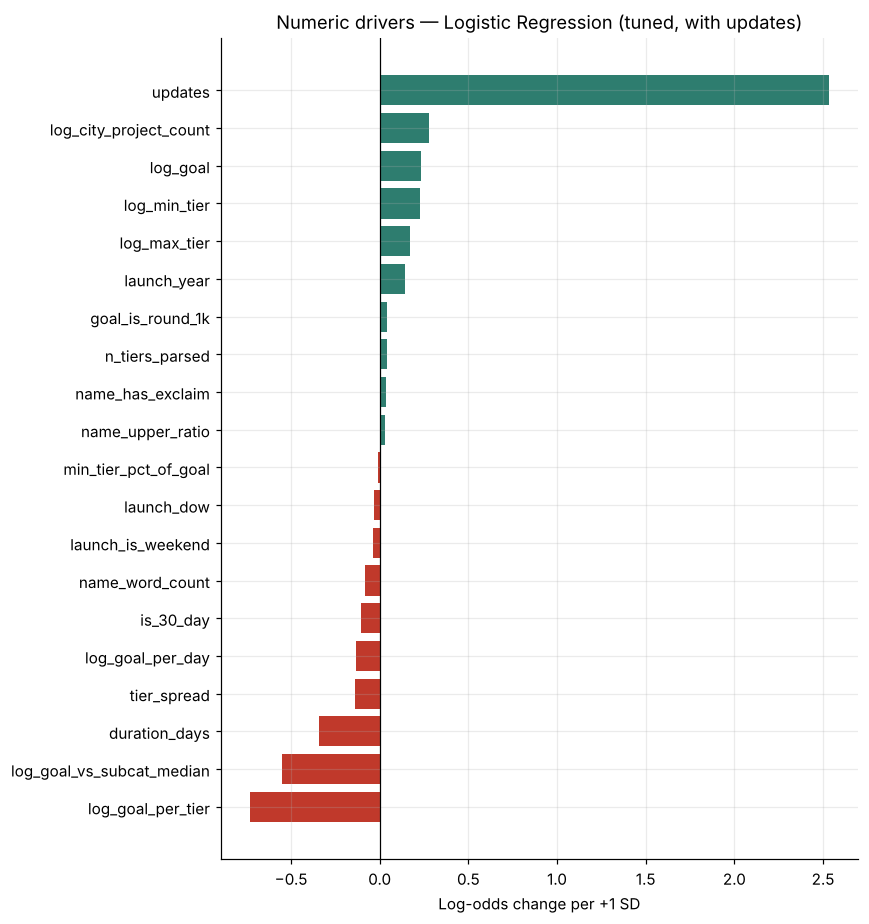

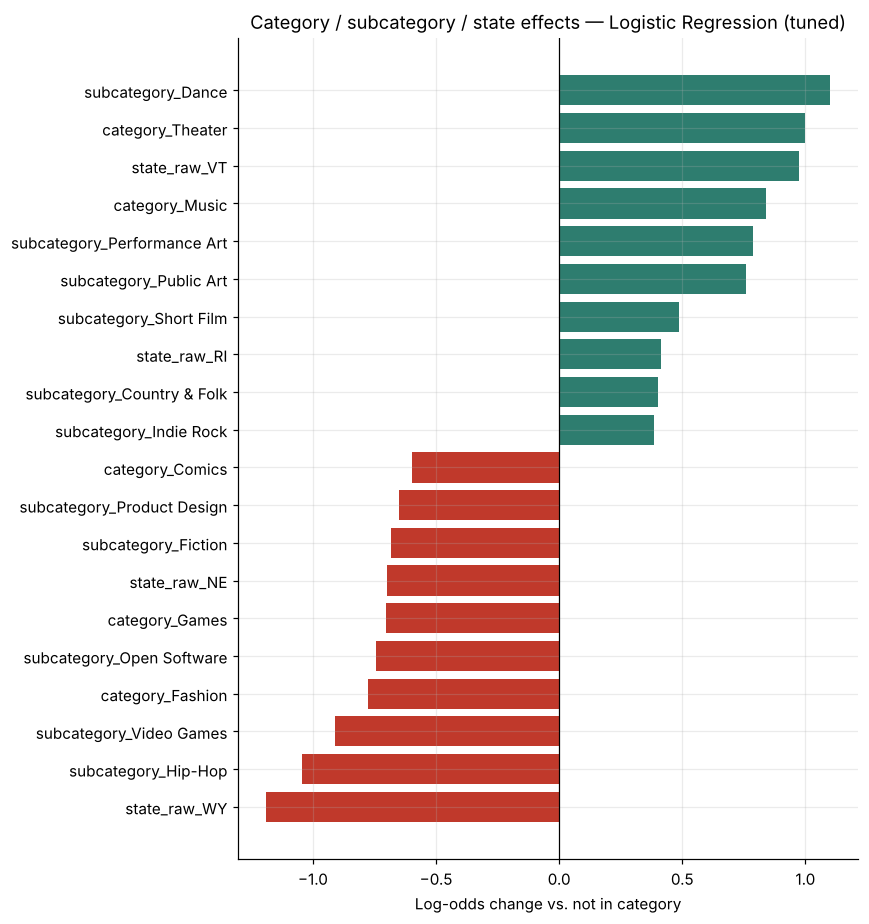

In [22]:
def plot_bars(df, value, title, xlabel, path, top_n=10):
    df = df[df[value] != 0]
    plot_df = pd.concat([df[df[value] > 0].nlargest(top_n, value),
                         df[df[value] < 0].nsmallest(top_n, value)]).sort_values(value)
    colors = np.where(plot_df[value] > 0, TEAL, CORAL)
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(plot_df) + 1.5))
    ax.barh(plot_df["feature"], plot_df[value], color=colors)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel(xlabel); ax.set_title(title)
    fig.tight_layout(); fig.savefig(path, dpi=130, bbox_inches="tight"); plt.show()

plot_bars(numeric, "coef_per_sd", "Numeric drivers — Logistic Regression (tuned, with updates)",
          "Log-odds change per +1 SD", FIG / "m3_lr_numeric_drivers.png")
plot_bars(coefs[coefs.kind == "categorical"], "coef_per_unit",
          "Category / subcategory / state effects — Logistic Regression (tuned)",
          "Log-odds change vs. not in category", FIG / "m3_lr_categorical_effects.png")

#### Result (Task 7 · Logistic Regression)

- **Launch-time only: 71.6% accuracy, ROC-AUC 0.777** on the random split,
  about 17 points above the 54.7% floor.
- **With `updates`: 81.6% accuracy, ROC-AUC 0.894** (+10.0 points of
  accuracy). On later campaigns (chronological split): 71.8% → 79.9%.
- **Tuning** (L1/L2 penalty, `C`) changes these by hundredths of a point.
- **`updates` has by far the largest coefficient.** Goal per reward tier,
  campaign length and goal relative to the subcategory norm lower the odds;
  city size raises them. The goal-derived features are collinear, so read
  their coefficients as a group.
- Not chosen as the final *predictor* (Task 10), but its smooth, readable
  response makes it the **advisor** that estimates what-if effects in the
  recommendation prototype (notebook 03).

### 7b — Random Forest

*Built by James Lu.*

A Random Forest builds many decision trees, each on a random subsample of
rows and considering a random subset of features at each split, then
averages their votes. Individual trees overfit badly; averaging many
decorrelated ones cancels most of that out.

**It assumes almost nothing** — no linearity, no scaling — and it finds
interactions automatically. If high goals are only damaging when there are
few reward tiers, some tree will split on it without being told to.

In [23]:
rf_res = run_four("Random Forest", lambda: make_models()["Random Forest"])
rf_res.round(4)

,model,feature_set,split,accuracy,precision,recall,f1,roc_auc
0,Random Forest,launch_only,random,0.7153,0.7041,0.8277,0.7609,0.7798
1,Random Forest,with_updates,random,0.8180,0.8158,0.8622,0.8383,0.8972
2,Random Forest,launch_only,chronological,0.7200,0.7037,0.8232,0.7588,0.7906
3,Random Forest,with_updates,chronological,0.8056,0.8094,0.8327,0.8209,0.8898


In [24]:
print("What adding `updates` does (random split):")
before_after(rf_res).round(4)

What adding `updates` does (random split):


,launch-time only,with updates,change
accuracy,0.7153,0.8180,0.1027
f1,0.7609,0.8383,0.0774
roc_auc,0.7798,0.8972,0.1174


In [25]:
print("Random vs chronological split:")
rf_res.pivot(index="split", columns="feature_set", values="accuracy").round(4)

Random vs chronological split:


feature_set,launch_only,with_updates
split,,
chronological,0.7200,0.8056
random,0.7153,0.8180


In [26]:
rf_model = make_models()["Random Forest"].fit(X_train, y_train)
confusion_frame(rf_model, X_test, y_test)

,predicted: failed,predicted: successful
actual: failed,2657,818
actual: successful,579,3622


**Notes for tuning (Task 9).**

- Do **not** use the built-in `feature_importances_`. That is Gini
  importance, which is biased toward continuous and high-cardinality
  features. Tasks 9 and 10 use permutation importance instead.
- `min_samples_leaf` is the main lever against overfitting.
- More trees is more stable, with sharply diminishing returns past a few
  hundred.

#### Result (Task 7 · Random Forest)

- **Launch-time only: 71.5% accuracy, F1 0.761, ROC-AUC 0.780** with
  default settings.
- **With `updates`: 81.8% accuracy, F1 0.838, ROC-AUC 0.897** (+10.3
  points of accuracy), the highest of the three default models, 0.2 points
  ahead of Logistic Regression.
- **Later campaigns:** 72.0% → 80.6%, so the random split is not flattering it.
- After tuning (Task 9) and calibration (Task 10) this model becomes the
  project's **final model**.

### 7c — KNN

*Built by Menwe Okafor. The two KNN notebooks (`06c_knn` and
`06c_knn complete`) held the same code; they are merged here.*

K-Nearest Neighbors has no training phase. It memorises the training set,
and to classify a new campaign it finds the `k` most similar ones by
Euclidean distance and takes a majority vote.

**Scaling is mandatory** — unscaled, `log_goal` would dominate the
distance calculation and the binary flags would be invisible.
`make_models()` handles this.

**Expect this model to underperform, and do not treat that as a bug.**
After one-hot encoding the matrix has about 137 columns, and in high
dimensions distances concentrate: the nearest and farthest neighbours end
up almost equidistant, so "nearest" stops meaning "similar". One-hot
encoding makes it worse, since 49 subcategory columns each contribute to
distance while only one is ever 1. It also means `updates`, one column among
138, moves KNN much less than it moves the other two models.

In [27]:
knn_res = run_four("KNN", lambda: make_models()["KNN"])
knn_res.round(4)

,model,feature_set,split,accuracy,precision,recall,f1,roc_auc
0,KNN,launch_only,random,0.6528,0.6453,0.8119,0.7191,0.7026
1,KNN,with_updates,random,0.6855,0.6746,0.8217,0.7409,0.7413
2,KNN,launch_only,chronological,0.6567,0.6508,0.7730,0.7067,0.7138
3,KNN,with_updates,chronological,0.6794,0.6765,0.7679,0.7193,0.7410


In [28]:
print("What adding `updates` does (random split):")
before_after(knn_res).round(4)

What adding `updates` does (random split):


,launch-time only,with updates,change
accuracy,0.6528,0.6855,0.0327
f1,0.7191,0.7409,0.0218
roc_auc,0.7026,0.7413,0.0387


In [29]:
print("Random vs chronological split:")
knn_res.pivot(index="split", columns="feature_set", values="accuracy").round(4)

Random vs chronological split:


feature_set,launch_only,with_updates
split,,
chronological,0.6567,0.6794
random,0.6528,0.6855


In [30]:
knn_model = make_models()["KNN"].fit(X_train, y_train)
confusion_frame(knn_model, X_test, y_test)

,predicted: failed,predicted: successful
actual: failed,1810,1665
actual: successful,749,3452


#### Result (Task 7 · KNN)

- **Launch-time only: 65.3% accuracy** (floor 54.7%, so +10.6 points).
- **With `updates`: 68.6%** (+3.3 points); ROC-AUC 0.703 → 0.741. On later
  campaigns: 65.7% → 67.9%, about the same as the random split.
- **The smallest gain from `updates` of the three models**, as expected: one
  column among 138 barely moves a Euclidean distance.
- It leans toward predicting "success": with `updates`, recall is 0.82 but
  precision only 0.67, so it flags many failures as successes (more false
  positives than false negatives in the confusion matrix).

**Things to watch with this model:** `n_neighbors` is the whole model (small
values are noisy; large values smooth toward the majority class), and
prediction is slow because every prediction scans the training set.

### Save the Task 7 results

In [31]:
t7 = pd.concat([lr_res, lr_tuned_res, rf_res, knn_res], ignore_index=True)
t7.to_csv(REPORTS / "m3_task7_model_results.csv", index=False)
print(f"Wrote m3_task7_model_results.csv ({len(t7)} rows: 3 models + tuned LR, "
      f"2 feature sets, 2 splits)")

Wrote m3_task7_model_results.csv (16 rows: 3 models + tuned LR, 2 feature sets, 2 splits)


## Task 8 — Compare Model Performance

**Milestone 3 · Task 8.** Evaluate all models on Accuracy, Precision,
Recall, F1-score and ROC-AUC. Produce a comparison table and visualisation
identifying which perform best and where they differ.

### 8.1 The comparison table

Final feature set (`with_updates`), random split, against the floor.

In [32]:
base3 = pd.concat([lr_res, rf_res, knn_res], ignore_index=True)
primary = base3[(base3.feature_set == FINAL_FEATURE_SET) & (base3.split == "random")]
table = pd.concat([floor, primary], ignore_index=True).sort_values("f1", ascending=False)
table = table.reset_index(drop=True)
table[["model"] + METRICS].round(4)

,model,accuracy,precision,recall,f1,roc_auc
0,Random Forest,0.8180,0.8158,0.8622,0.8383,0.8972
1,Logistic Regression,0.8158,0.8254,0.8415,0.8333,0.8936
2,KNN,0.6855,0.6746,0.8217,0.7409,0.7413
3,Majority class,0.5473,0.5473,1.0000,0.7074,0.5000


### 8.2 Metrics side by side

Reading all five together matters. A model can win on accuracy and lose on
recall, and which you prefer depends on whether a false encouragement or a
false discouragement is the worse outcome.

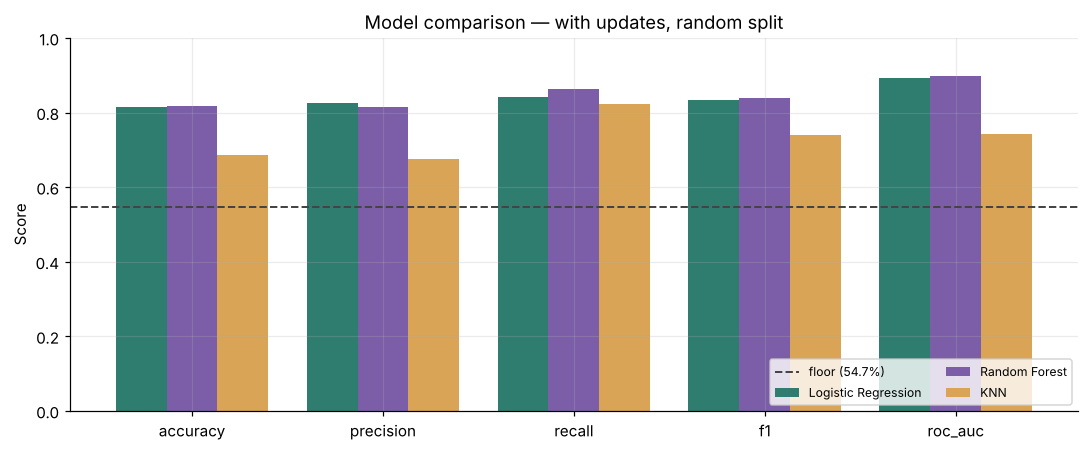

In [33]:
models = primary.model.tolist()
x = np.arange(len(METRICS))
w = 0.8 / len(models)
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, (m, c) in enumerate(zip(models, [TEAL, PLUM, SAND])):
    row = primary[primary.model == m].iloc[0]
    ax.bar(x + i * w, [row[k] for k in METRICS], w, label=m, color=c)
ax.axhline(FLOOR_ACC, color="#444", ls="--", lw=1.3, label=f"floor ({FLOOR_ACC:.1%})")
ax.set_xticks(x + w * (len(models) - 1) / 2)
ax.set_xticklabels(METRICS)
ax.set_ylim(0, 1.0); ax.set_ylabel("Score")
ax.set_title("Model comparison — with updates, random split")
ax.legend(fontsize=8, ncol=2, loc="lower right")
plt.tight_layout()
plt.savefig(FIG / "m3_model_comparison.png", dpi=130, bbox_inches="tight")
plt.show()

### 8.3 ROC curves

ROC-AUC does not depend on the 0.5 decision threshold. Two models can share
an accuracy score while ranking campaigns very differently.

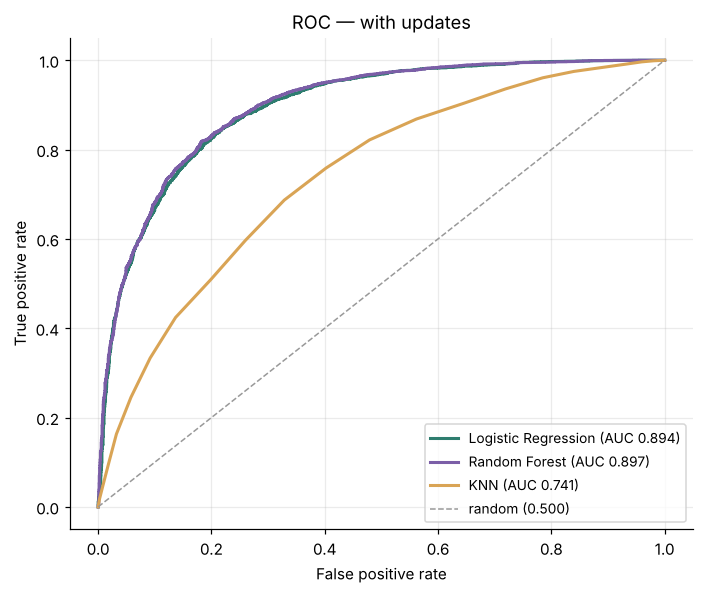

In [34]:
fitted = {"Logistic Regression": lr_model, "Random Forest": rf_model, "KNN": knn_model}
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for (label, model), c in zip(fitted.items(), [TEAL, PLUM, SAND]):
    fpr, tpr, auc = roc_points(model, X_test, y_test)
    ax.plot(fpr, tpr, color=c, lw=2, label=f"{label} (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], color="#999", ls="--", lw=1, label="random (0.500)")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC — with updates")
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout()
plt.savefig(FIG / "m3_roc_curves.png", dpi=130, bbox_inches="tight")
plt.show()

### 8.4 What adding `updates` did to each model

The same model, the same rows, the same settings; the only difference is the
one extra column. This is the before-and-after the project's headline numbers
rest on.

In [35]:
rows = []
for name, res in [("Logistic Regression", lr_res), ("Random Forest", rf_res), ("KNN", knn_res)]:
    for split_name in SPLITS:
        r = res[res["split"] == split_name].set_index("feature_set")
        for metric in ["accuracy", "f1", "roc_auc"]:
            a, b = r.loc["launch_only", metric], r.loc["with_updates", metric]
            rows.append({"model": name, "split": split_name, "metric": metric,
                         "launch_only": a, "with_updates": b, "change": b - a})
updates_effect = pd.DataFrame(rows)
updates_effect.to_csv(REPORTS / "m3_updates_effect.csv", index=False)

acc = updates_effect[updates_effect.metric == "accuracy"].copy()
acc["before -> after"] = [f"{a:.1%} -> {b:.1%} ({(b - a) * 100:+.1f} pts)"
                          for a, b in zip(acc.launch_only, acc.with_updates)]
acc.pivot(index="model", columns="split", values="before -> after")

split,chronological,random
model,,
KNN,65.7% -> 67.9% (+2.3 pts),65.3% -> 68.6% (+3.3 pts)
Logistic Regression,71.8% -> 79.9% (+8.1 pts),71.6% -> 81.6% (+10.0 pts)
Random Forest,72.0% -> 80.6% (+8.6 pts),71.5% -> 81.8% (+10.3 pts)


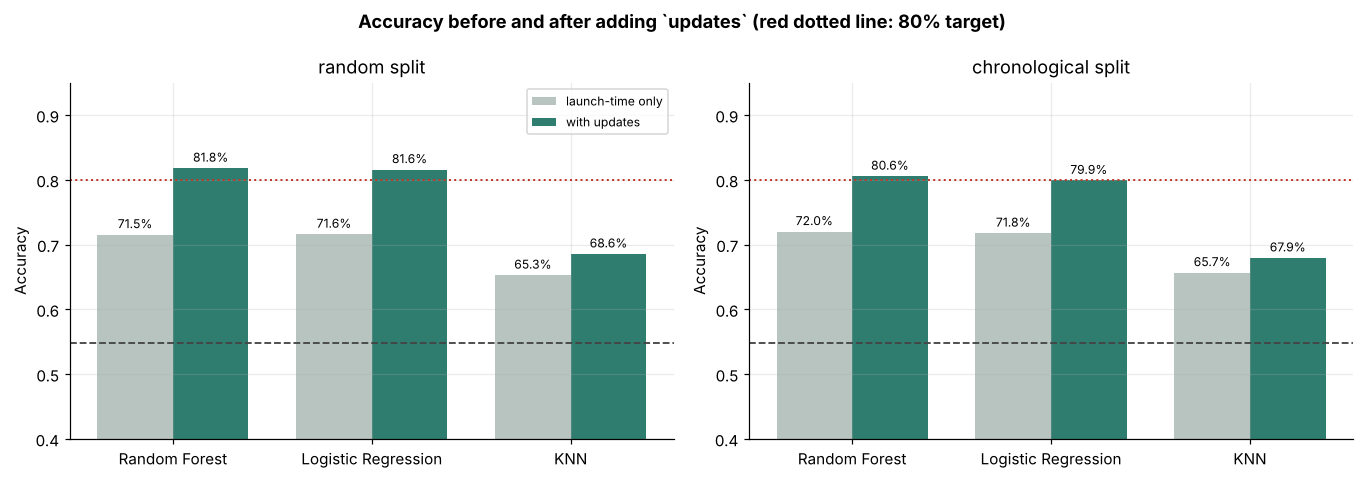

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
for ax, split_name in zip(axes, SPLITS):
    a = acc[acc.split == split_name].set_index("model").loc[["Random Forest", "Logistic Regression", "KNN"]]
    xx = np.arange(len(a)); ww = 0.38
    ax.bar(xx - ww / 2, a["launch_only"], ww, color="#B8C4C0", label="launch-time only")
    ax.bar(xx + ww / 2, a["with_updates"], ww, color=TEAL, label="with updates")
    for i, (b0, b1) in enumerate(zip(a["launch_only"], a["with_updates"])):
        ax.text(i - ww / 2, b0 + 0.01, f"{b0:.1%}", ha="center", fontsize=8)
        ax.text(i + ww / 2, b1 + 0.01, f"{b1:.1%}", ha="center", fontsize=8)
    ax.axhline(FLOOR_ACC, color="#444", ls="--", lw=1.2)
    ax.axhline(0.80, color=CORAL, ls=":", lw=1.3)
    ax.set_xticks(xx); ax.set_xticklabels(a.index)
    ax.set_ylim(0.4, 0.95); ax.set_ylabel("Accuracy")
    ax.set_title(f"{split_name} split")
axes[0].legend(fontsize=8, loc="upper right")
fig.suptitle("Accuracy before and after adding `updates` (red dotted line: 80% target)",
             fontweight="bold")
plt.tight_layout()
plt.savefig(FIG / "m3_updates_effect.png", dpi=130, bbox_inches="tight")
plt.show()

**Reading it.** `updates` adds about 10 points of accuracy to the Random
Forest (71.5% → 81.8%) and to Logistic Regression (71.6% → 81.6%) on the
random split, and 8–9 points on later campaigns. KNN gains about 3 points
(65.3% → 68.6%). Only with `updates` do the two stronger models reach the
brief's ~80% target: on later campaigns the Random Forest lands just over it
(80.6%) and Logistic Regression just under (79.9%).

These gains use each campaign's *final* update count. For a creator planning
a campaign they are an upper bound: a plan can be wrong, and part of the
signal is campaigns that were already succeeding posting more.

### 8.5 Threshold sensitivity

Every metric above assumes a 0.5 cutoff. Moving it trades precision against
recall.

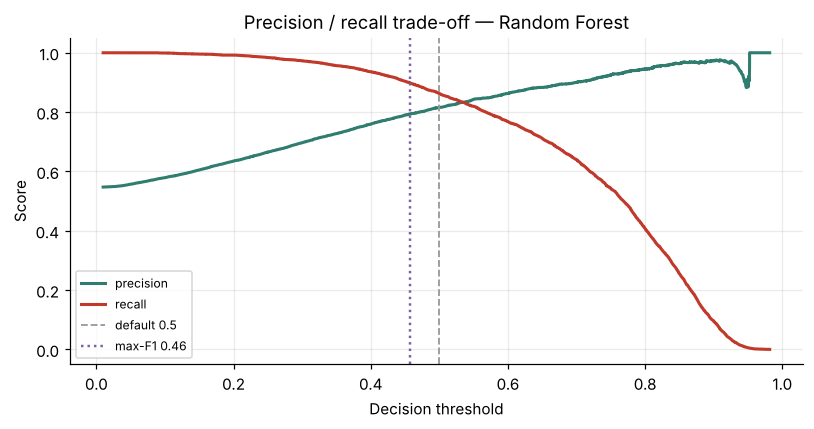

Default threshold 0.50 -> F1 0.838
Best threshold 0.46 -> F1 0.844


In [37]:
from sklearn.metrics import precision_recall_curve

leader_name = primary.sort_values("f1", ascending=False).model.iloc[0]
leader = fitted[leader_name]
proba = leader.predict_proba(X_test)[:, 1]
prec, rec_, thr = precision_recall_curve(y_test, proba)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(thr, prec[:-1], color=TEAL, lw=2, label="precision")
ax.plot(thr, rec_[:-1], color=CORAL, lw=2, label="recall")
f1_curve = 2 * prec[:-1] * rec_[:-1] / np.clip(prec[:-1] + rec_[:-1], 1e-9, None)
best_thr = thr[int(np.argmax(f1_curve))]
ax.axvline(0.5, color="#999", ls="--", lw=1.2, label="default 0.5")
ax.axvline(best_thr, color=PLUM, ls=":", lw=1.6, label=f"max-F1 {best_thr:.2f}")
ax.set_xlabel("Decision threshold"); ax.set_ylabel("Score")
ax.set_title(f"Precision / recall trade-off — {leader_name}")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "m3_threshold_tradeoff.png", dpi=130, bbox_inches="tight")
plt.show()

print(f"Default threshold 0.50 -> F1 {f1_curve[np.argmin(np.abs(thr - 0.5))]:.3f}")
print(f"Best threshold {best_thr:.2f} -> F1 {f1_curve.max():.3f}")

### 8.6 Candidates to carry into tuning

In [38]:
ranked = primary.sort_values("f1", ascending=False)[["model"] + METRICS].round(4)
print(ranked.to_string(index=False))
print(f"\nCarrying forward the top two by F1: {', '.join(ranked.model.head(2))}")
table.to_csv(REPORTS / "m3_task8_comparison.csv", index=False)
print("\nWrote m3_task8_comparison.csv and m3_updates_effect.csv")

              model  accuracy  precision  recall     f1  roc_auc
      Random Forest    0.8180     0.8158  0.8622 0.8383   0.8972
Logistic Regression    0.8158     0.8254  0.8415 0.8333   0.8936
                KNN    0.6855     0.6746  0.8217 0.7409   0.7413

Carrying forward the top two by F1: Random Forest, Logistic Regression

Wrote m3_task8_comparison.csv and m3_updates_effect.csv


### Task 8 — Summary

- **Final feature set, random split:** Random Forest 81.8% accuracy / F1
  0.838 / ROC-AUC 0.897; Logistic Regression 81.6% / 0.833 / 0.894; KNN
  68.6% / 0.741 / 0.741; floor 54.7%.
- **Random Forest and Logistic Regression are effectively level** (0.2
  points of accuracy, 0.004 ROC-AUC). KNN is about 13 points behind.
- **What `updates` is worth is measured for every model** (§8.4, saved as
  `reports/m3_updates_effect.csv`): about +10 points for the two stronger
  models, +3 for KNN.
- The default 0.5 threshold is a choice, not a law (§8.5).
- **Carried into tuning:** Random Forest and Logistic Regression.

## Task 9 — Feature Selection and Model Tuning

**Milestone 3 · Task 9.** Review the feature set, create new features where
useful and remove those that add noise. Tune the strongest models using
cross-validation, and investigate whether class balancing improves results.

Everything here uses the final feature set (`with_updates`) on the random
split. All tuning uses cross-validation **on the training split only**; the
test set is touched once, at the end, to report the tuned result.

In [39]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

print(f"X_train {X_train.shape}   X_test {X_test.shape}   ({FINAL_FEATURE_SET})")
print(f"Class balance: {y_train.mean():.2%} successful")

X_train (30702, 138)   X_test (7676, 138)   (with_updates)
Class balance: 54.74% successful


### 9.1 Does class balancing help?

At 54.7/45.3 the imbalance is mild, so the honest expectation is "not much",
but it is measured rather than assumed.

In [40]:
bal_rows = []
for weight in [None, "balanced"]:
    for name, mk in [
        ("Logistic Regression", lambda w: Pipeline([
            ("scale", StandardScaler()),
            ("clf", LogisticRegression(max_iter=2000, class_weight=w, random_state=RANDOM_STATE))])),
        ("Random Forest", lambda w: RandomForestClassifier(
            n_estimators=200, min_samples_leaf=5, class_weight=w,
            random_state=RANDOM_STATE, n_jobs=-1)),
    ]:
        m = mk(weight).fit(X_train, y_train)
        r = evaluate(m, X_test, y_test, label=name, feature_set=FINAL_FEATURE_SET, split="random")
        r["class_weight"] = str(weight)
        bal_rows.append(r)
bal = pd.concat(bal_rows, ignore_index=True)
bal.pivot_table(index="model", columns="class_weight",
                values=["accuracy", "precision", "recall", "f1"]).round(4)

accuracy               f1          precision           recall         
class_weight            None balanced    None balanced      None balanced    None balanced
model                                                                                     
Logistic Regression   0.8158   0.8115  0.8333   0.8248    0.8254   0.8392  0.8415   0.8110
Random Forest         0.8168   0.8181  0.8372   0.8338    0.8152   0.8340  0.8603   0.8336

### 9.2 A new feature: `log(updates)`

`updates` is heavily skewed (median 2, maximum 149). A tree does not care,
since it only splits on thresholds, but a linear model treats the hundredth
update as worth as much as the first. Test whether a log transform helps.

In [41]:
def with_log_updates(X):
    X = X.copy()
    X["log_updates"] = np.log1p(X["updates"])
    return X.drop(columns="updates")

Xl_tr, Xl_te = with_log_updates(X_train), with_log_updates(X_test)
log_rows = []
for name in ["Logistic Regression", "Random Forest"]:
    for label_, (A, B) in [("updates (raw count)", (X_train, X_test)),
                           ("log(1 + updates)", (Xl_tr, Xl_te))]:
        m = make_models()[name].fit(A, y_train)
        log_rows.append(evaluate(m, B, y_test, label=name, feature_set=label_, split="random"))
log_check = pd.concat(log_rows, ignore_index=True)
log_check[["model", "feature_set"] + METRICS].round(4)

,model,feature_set,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,updates (raw count),0.8158,0.8254,0.8415,0.8333,0.8936
1,Logistic Regression,log(1 + updates),0.8232,0.8302,0.8510,0.8405,0.9032
2,Random Forest,updates (raw count),0.8180,0.8158,0.8622,0.8383,0.8972
3,Random Forest,log(1 + updates),0.8190,0.8167,0.8631,0.8393,0.8976


**Result.** The log transform lifts Logistic Regression from 81.6% to
**82.3%** accuracy (ROC-AUC 0.894 → 0.903), ahead of every Random Forest in
this notebook. The Random Forest barely moves (81.8% → 81.9%), as expected
for a tree.

**Decision:** the final feature set keeps the raw count. The team chose the
Random Forest as the final model (Task 10), and for it the transform changes
nothing. The Logistic Regression result is recorded rather than hidden: a
log-updates Logistic Regression is a credible alternative final model, about
0.7 points ahead on accuracy.

### 9.3 Feature selection by permutation importance

Permutation importance measures how much ROC-AUC drops when a column is
shuffled. Unlike Gini importance it is not biased toward continuous or
high-cardinality features, and it is measured on held-out data. Computed on
a 2,000-row subsample with 3 repeats for speed.

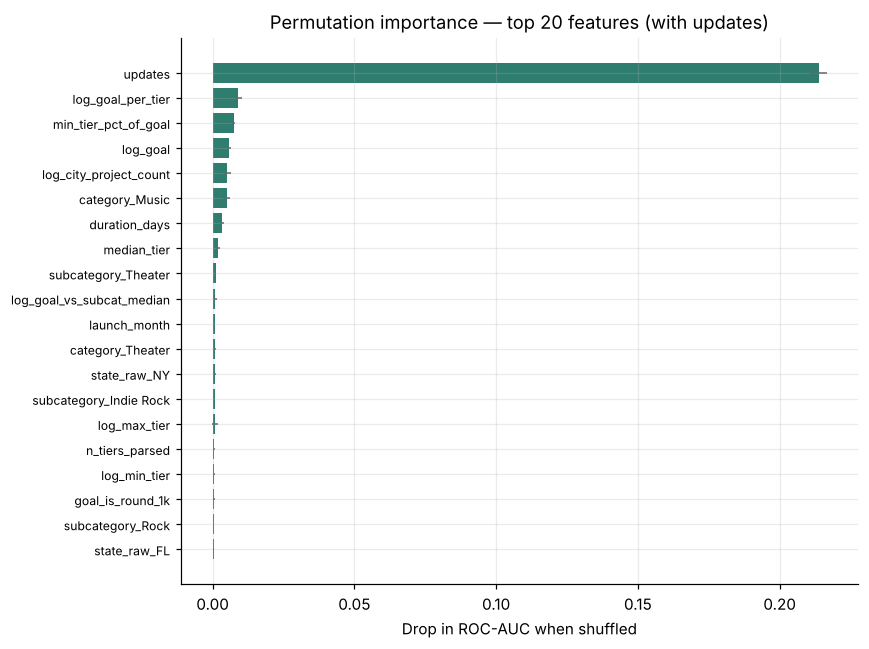

,feature,importance,std
22,updates,0.21373,0.00304
12,log_goal_per_tier,0.00909,0.00119
11,min_tier_pct_of_goal,0.00742,0.00056
0,log_goal,0.00593,0.00051
23,log_city_project_count,0.00512,0.00118
33,category_Music,0.00492,0.00112
2,duration_days,0.00335,0.00052
9,median_tier,0.00199,0.00073
83,subcategory_Theater,0.00102,0.00022
24,log_goal_vs_subcat_median,0.00094,0.00057


In [42]:
base_rf = RandomForestClassifier(n_estimators=150, min_samples_leaf=5,
                                 random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
sub_ = X_test.sample(n=min(2000, len(X_test)), random_state=RANDOM_STATE)
perm = permutation_importance(base_rf, sub_, y_test.loc[sub_.index], n_repeats=3,
                              random_state=RANDOM_STATE, n_jobs=-1, scoring="roc_auc")
imp = pd.DataFrame({"feature": X_train.columns, "importance": perm.importances_mean,
                    "std": perm.importances_std}).sort_values("importance", ascending=False)

top = imp.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(range(len(top)), top["importance"], xerr=top["std"], color=TEAL,
        error_kw={"ecolor": "#666", "lw": 1})
ax.set_yticks(range(len(top))); ax.set_yticklabels(top["feature"], fontsize=8)
ax.set_xlabel("Drop in ROC-AUC when shuffled")
ax.set_title("Permutation importance — top 20 features (with updates)")
plt.tight_layout()
plt.savefig(FIG / "m3_permutation_importance.png", dpi=130, bbox_inches="tight")
plt.show()
imp.head(10).round(5)

#### Pruning the noise

Features with importance at or below zero did not help on held-out data.
Dropping them tests whether a smaller feature set performs as well.

In [43]:
useful = imp[imp.importance > 0.0001]["feature"].tolist()
dead = imp[imp.importance <= 0]["feature"].tolist()
print(f"Features with positive importance: {len(useful)} of {X_train.shape[1]}")
print(f"Features with zero or negative:    {len(dead)}")

prune_rows = []
for name, cols in [("all features", list(X_train.columns)), ("pruned", useful)]:
    m = RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                               random_state=RANDOM_STATE, n_jobs=-1).fit(X_train[cols], y_train)
    r = evaluate(m, X_test[cols], y_test, label=f"RF — {name}",
                 feature_set=FINAL_FEATURE_SET, split="random")
    r["n_features"] = len(cols)
    prune_rows.append(r)
pd.concat(prune_rows, ignore_index=True)[["model", "n_features"] + METRICS].round(4)

Features with positive importance: 33 of 138
Features with zero or negative:    63


,model,n_features,accuracy,precision,recall,f1,roc_auc
0,RF — all features,138,0.8168,0.8152,0.8603,0.8372,0.8961
1,RF — pruned,33,0.8166,0.8205,0.8510,0.8355,0.8980


### 9.4 Hyperparameter tuning

`RandomizedSearchCV` rather than an exhaustive grid, scored on ROC-AUC
because it is threshold-free: 10 candidates for the Random Forest and 6 for
Logistic Regression, each with 3-fold cross-validation.

In [44]:
rf_space = {
    "n_estimators": [200, 300, 400],
    "max_depth": [None, 12, 20],
    "min_samples_leaf": [3, 5, 10, 20],
    "max_features": ["sqrt", "log2", 0.3],
}
rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    rf_space, n_iter=10, cv=3, scoring="roc_auc", random_state=RANDOM_STATE, n_jobs=-1,
).fit(X_train, y_train)
print("Random Forest")
print(f"  best CV ROC-AUC: {rf_search.best_score_:.4f}")
print(f"  best params:     {rf_search.best_params_}")

lr_space = {"clf__C": [0.03, 0.3, 1.0, 3.0], "clf__penalty": ["l2"],
            "clf__class_weight": [None, "balanced"]}
lr_search = RandomizedSearchCV(
    Pipeline([("scale", StandardScaler()),
              ("clf", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))]),
    lr_space, n_iter=6, cv=3, scoring="roc_auc", random_state=RANDOM_STATE, n_jobs=-1,
).fit(X_train, y_train)
print("Logistic Regression")
print(f"  best CV ROC-AUC: {lr_search.best_score_:.4f}")
print(f"  best params:     {lr_search.best_params_}")

Random Forest
  best CV ROC-AUC: 0.8963
  best params:     {'n_estimators': 400, 'min_samples_leaf': 3, 'max_features': 0.3, 'max_depth': 12}


Logistic Regression
  best CV ROC-AUC: 0.8914
  best params:     {'clf__penalty': 'l2', 'clf__class_weight': None, 'clf__C': 1.0}


### 9.5 Tuned results on the held-out test set

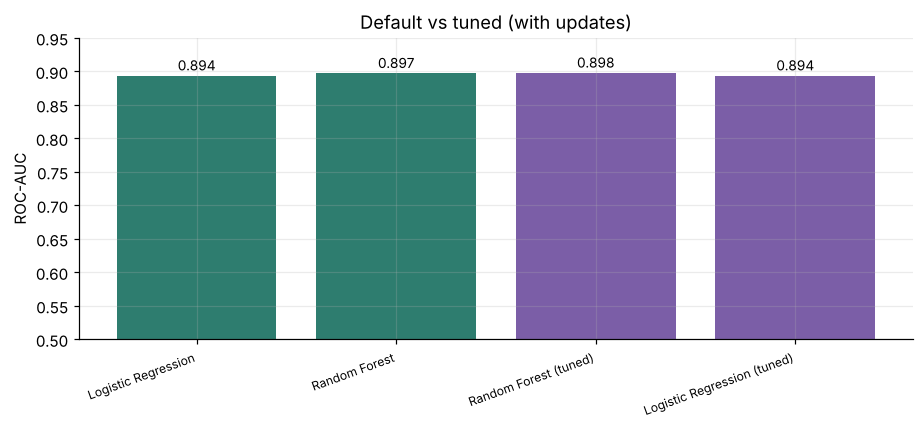

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.8158,0.8254,0.8415,0.8333,0.8936
1,Random Forest,0.8180,0.8158,0.8622,0.8383,0.8972
2,Random Forest (tuned),0.8157,0.8244,0.8427,0.8334,0.8978
3,Logistic Regression (tuned),0.8158,0.8254,0.8415,0.8333,0.8936


In [45]:
tuned = pd.concat([
    evaluate(rf_search.best_estimator_, X_test, y_test, label="Random Forest (tuned)",
             feature_set=FINAL_FEATURE_SET, split="random"),
    evaluate(lr_search.best_estimator_, X_test, y_test, label="Logistic Regression (tuned)",
             feature_set=FINAL_FEATURE_SET, split="random"),
], ignore_index=True)
baseline = primary[primary.model.isin(["Random Forest", "Logistic Regression"])]
comp = pd.concat([baseline, tuned], ignore_index=True)

fig, ax = plt.subplots(figsize=(8.5, 4))
xx = np.arange(len(comp))
ax.bar(xx, comp["roc_auc"], color=[PLUM if "tuned" in m else TEAL for m in comp.model])
ax.set_xticks(xx); ax.set_xticklabels(comp.model, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("ROC-AUC"); ax.set_ylim(0.5, 0.95); ax.set_title("Default vs tuned (with updates)")
for i, v in enumerate(comp["roc_auc"]):
    ax.text(i, v + 0.008, f"{v:.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(FIG / "m3_tuning_effect.png", dpi=130, bbox_inches="tight")
plt.show()
comp[["model"] + METRICS].round(4)

### 9.6 Save the tuned configuration

Saved as JSON rather than a pickled model, so Task 10 and `src/modeling.py`
rebuild the exact estimator without a binary artefact in the repo.

In [46]:
config = {
    "feature_set": FINAL_FEATURE_SET,
    "random_forest": {k: (int(v) if isinstance(v, np.integer) else v)
                      for k, v in rf_search.best_params_.items()},
    "logistic_regression": {k.replace("clf__", ""): v for k, v in lr_search.best_params_.items()},
    "rf_cv_roc_auc": round(float(rf_search.best_score_), 4),
    "lr_cv_roc_auc": round(float(lr_search.best_score_), 4),
    "pruned_features": useful,
    "n_features_all": int(X_train.shape[1]),
    "n_features_pruned": len(useful),
}
(REPORTS / "m3_tuned_config.json").write_text(json.dumps(config, indent=2))
pd.concat([tuned, bal.assign(model=bal.model + " (class_weight=" + bal.class_weight + ")")
                     .drop(columns="class_weight"),
           log_check.assign(model=log_check.model + " — " + log_check.feature_set,
                            feature_set=FINAL_FEATURE_SET)],
          ignore_index=True).to_csv(REPORTS / "m3_task9_tuned_results.csv", index=False)
print("Wrote m3_tuned_config.json and m3_task9_tuned_results.csv")

Wrote m3_tuned_config.json and m3_task9_tuned_results.csv


### Task 9 — Summary

- **Class balancing** does not raise accuracy (Logistic Regression 81.6% →
  81.1%, Random Forest 81.7% → 81.8%); it trades recall for precision.
- **`log(updates)`** adds 0.7 points to Logistic Regression and almost
  nothing to the Random Forest; not adopted (§9.2).
- **Permutation importance:** `updates` dominates (ROC-AUC drops 0.21 when it
  is shuffled, against 0.009 for the next feature). 33 of 138 columns have
  positive importance; a forest on those 33 matches the full one (81.7% both,
  ROC-AUC 0.896 vs 0.898). The full set is kept, so the prototype accepts any
  category, subcategory and state.
- **Tuning:** best Random Forest CV ROC-AUC 0.896 with 400 trees, maximum
  depth 12, minimum leaf 3 and 30% of features per split. On the test set
  ROC-AUC goes 0.897 → 0.898 but accuracy 81.8% → 81.6%, because the search
  optimises ROC-AUC. Logistic Regression's best setting is the default
  `C = 1.0`.
- As without `updates`, the binding constraint is the information in the
  data, not the algorithm or its settings.

## Task 10 — Interpretability and Final Model Selection

**Milestone 3 · Task 10.** Identify which features drive predictions, select
the best-performing model, and document its performance, strengths and
limitations.

**Decision recorded here: the final model is the tuned Random Forest, with
calibrated probabilities, on the `with_updates` feature set.** An earlier
draft chose Logistic Regression because the two were statistically level and
coefficients are easier to read; the team then chose the Random Forest. The
interpretability argument is met in two other ways: permutation importance
for the forest itself (§10.3), and Logistic Regression kept as the *advisor*
that estimates what-if effects in the Milestone 4 prototype.

In [47]:
tuned_rf = config["random_forest"]
same_params = all(FINAL_RF_PARAMS.get(k) == v for k, v in tuned_rf.items())
print(f"Tuned RF config (Task 9):          {tuned_rf}")
print(f"FINAL_RF_PARAMS (src/modeling.py): {FINAL_RF_PARAMS}")
print(f"They agree: {same_params}")
assert same_params, "Update FINAL_RF_PARAMS in src/modeling.py to the Task 9 result"

Tuned RF config (Task 9):          {'n_estimators': 400, 'min_samples_leaf': 3, 'max_features': 0.3, 'max_depth': 12}
FINAL_RF_PARAMS (src/modeling.py): {'n_estimators': 400, 'min_samples_leaf': 3, 'max_features': 0.3, 'max_depth': 12}
They agree: True


### 10.1 Rebuild the finalists

Three candidates on identical data: the tuned Random Forest, the tuned
Logistic Regression, and the tuned Random Forest wrapped in probability
calibration (`make_final_model()`).

In [48]:
rf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **FINAL_RF_PARAMS).fit(X_train, y_train)
lr = Pipeline([("scale", StandardScaler()),
               ("clf", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE,
                                          **config["logistic_regression"]))]).fit(X_train, y_train)
final_model = make_final_model().fit(X_train, y_train)

finalists = pd.concat([
    evaluate(final_model, X_test, y_test, label=FINAL_MODEL_NAME, feature_set=FINAL_FEATURE_SET, split="random"),
    evaluate(rf, X_test, y_test, label="Random Forest (tuned)", feature_set=FINAL_FEATURE_SET, split="random"),
    evaluate(lr, X_test, y_test, label="Logistic Regression (tuned)", feature_set=FINAL_FEATURE_SET, split="random"),
    floor,
], ignore_index=True)
finalists.round(4)

,model,feature_set,split,accuracy,precision,recall,f1,roc_auc
0,Random Forest (tuned + calibrated),with_updates,random,0.8155,0.8214,0.8472,0.8341,0.8976
1,Random Forest (tuned),with_updates,random,0.8157,0.8244,0.8427,0.8334,0.8978
2,Logistic Regression (tuned),with_updates,random,0.8158,0.8254,0.8415,0.8333,0.8936
3,Majority class,—,—,0.5473,0.5473,1.0000,0.7074,0.5000


#### Does it hold on later campaigns?

Refit on the chronological split (train on earlier campaigns, test on the
latest 20%).

In [49]:
train_c, test_c = SPLITS["chronological"]
Xc_tr, yc_tr, Xc_te, yc_te = model_matrices(train_c, test_c, FINAL_FEATURE_SET)
final_c = make_final_model().fit(Xc_tr, yc_tr)
lr_c = Pipeline([("scale", StandardScaler()),
                 ("clf", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE,
                                            **config["logistic_regression"]))]).fit(Xc_tr, yc_tr)
chrono = pd.concat([
    evaluate(final_c, Xc_te, yc_te, label=FINAL_MODEL_NAME, feature_set=FINAL_FEATURE_SET, split="chronological"),
    evaluate(lr_c, Xc_te, yc_te, label="Logistic Regression (tuned)", feature_set=FINAL_FEATURE_SET, split="chronological"),
    majority_class_baseline(yc_tr, yc_te).assign(split="chronological"),
], ignore_index=True)
chrono.round(4)

,model,feature_set,split,accuracy,precision,recall,f1,roc_auc
0,Random Forest (tuned + calibrated),with_updates,chronological,0.8048,0.8278,0.8020,0.8147,0.8874
1,Logistic Regression (tuned),with_updates,chronological,0.7991,0.8044,0.8251,0.8146,0.8807
2,Majority class,—,chronological,0.5349,0.5349,1.0000,0.6970,0.5000


### 10.2 Is the probability trustworthy?

The prototype shows a probability to a person, so a prediction of 30% has to
mean that about 30% of campaigns scored that way succeed. A Random Forest
averages tree votes, so its raw probabilities do not mean what they say;
calibration fixes the numbers without changing the ranking.

**A change made here.** The launch-time model used sigmoid (Platt)
calibration, which fits one S-shaped curve. With `updates` in the model that
made the worst decile *worse* than the raw forest, so two methods are
compared below and the final model uses the better one, **isotonic**
(a free-form increasing step function).

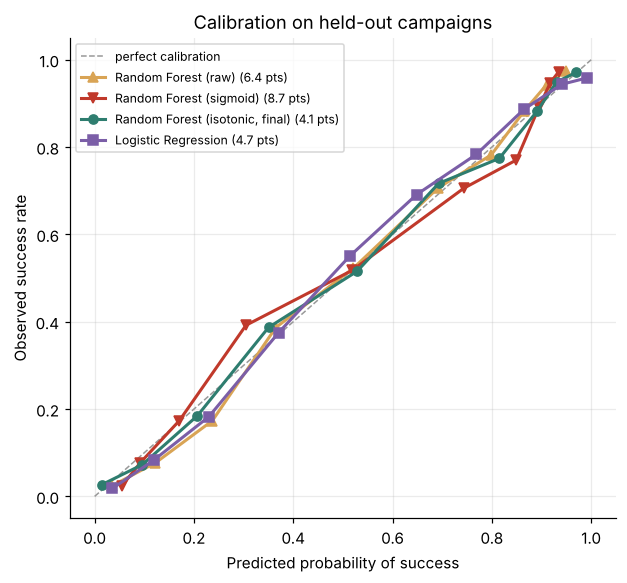

Random Forest (raw)                6.4
Random Forest (sigmoid)            8.7
Random Forest (isotonic, final)    4.1
Logistic Regression                4.7
Name: largest decile gap (pts), dtype: float64

In [50]:
from sklearn.calibration import CalibratedClassifierCV
rf_sigmoid = CalibratedClassifierCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **FINAL_RF_PARAMS),
    method="sigmoid", cv=3).fit(X_train, y_train)
curves = {"Random Forest (raw)": rf.predict_proba(X_test)[:, 1],
          "Random Forest (sigmoid)": rf_sigmoid.predict_proba(X_test)[:, 1],
          "Random Forest (isotonic, final)": final_model.predict_proba(X_test)[:, 1],
          "Logistic Regression": lr.predict_proba(X_test)[:, 1]}
cal_tables = {k: calibration_table(p, y_test) for k, p in curves.items()}
worst = pd.Series({k: t["gap_pp"].abs().max() for k, t in cal_tables.items()},
                  name="largest decile gap (pts)")

fig, ax = plt.subplots(figsize=(5.8, 5.4))
ax.plot([0, 1], [0, 1], color="#999", ls="--", lw=1, label="perfect calibration")
for (k, t), c, mk in zip(cal_tables.items(), [SAND, CORAL, TEAL, PLUM], ["^", "v", "o", "s"]):
    ax.plot(t["predicted"], t["observed"], marker=mk, color=c, lw=2, label=f"{k} ({worst[k]:.1f} pts)")
ax.set_xlabel("Predicted probability of success"); ax.set_ylabel("Observed success rate")
ax.set_title("Calibration on held-out campaigns"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "m3_calibration.png", dpi=130, bbox_inches="tight"); plt.show()
worst.round(1)

### 10.3 What drives the final model's predictions

**Permutation importance on held-out data**: shuffle one input and measure
how much ROC-AUC drops. Each numeric feature is shuffled on its own.
Category, subcategory and state are each shuffled **as a group** (all of
their one-hot columns together), because "subcategory" is one input to a
creator, not 49. `levels` and `n_tiers_parsed` are the same number, so they
are shuffled together as one input.

In [51]:
from sklearn.metrics import roc_auc_score

CAT_GROUPS = {"category": "category_", "subcategory": "subcategory_", "state": "state_raw_"}
groups = {c: [c] for c in X_test.columns if not c.startswith(tuple(CAT_GROUPS.values()))}
groups.update({g: [c for c in X_test.columns if c.startswith(p)] for g, p in CAT_GROUPS.items()})
groups.pop("levels"); groups.pop("n_tiers_parsed")
groups["n_reward_tiers"] = ["levels", "n_tiers_parsed"]

def grouped_permutation_importance(model, X, y, groups, n_repeats=5, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y, model.predict_proba(X)[:, 1])
    rows = []
    for name, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            idx = rng.permutation(len(X))
            Xp[cols] = X[cols].to_numpy()[idx]
            drops.append(base - roc_auc_score(y, model.predict_proba(Xp)[:, 1]))
        rows.append({"feature": name, "importance": np.mean(drops), "std": np.std(drops)})
    return pd.DataFrame(rows).sort_values("importance", ascending=False).reset_index(drop=True)

sub_ = X_test.sample(n=3000, random_state=RANDOM_STATE)
fimp = grouped_permutation_importance(final_model, sub_, y_test.loc[sub_.index], groups)
fimp.head(15).round(5)

,feature,importance,std
0,updates,0.25488,0.00494
1,log_goal_per_tier,0.02254,0.00261
2,log_goal,0.00967,0.00125
3,category,0.00728,0.00120
4,min_tier_pct_of_goal,0.00601,0.00092
5,log_city_project_count,0.00471,0.00100
6,duration_days,0.00310,0.00065
7,median_tier,0.00276,0.00054
8,subcategory,0.00232,0.00027
9,log_goal_vs_subcat_median,0.00152,0.00080


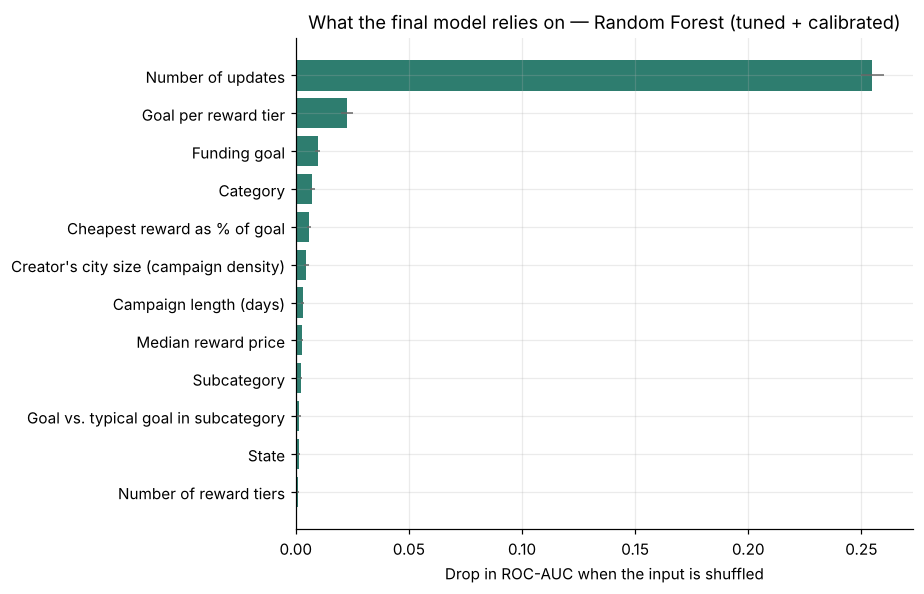

In [52]:
FRIENDLY = {
    "updates": "Number of updates", "log_goal_per_tier": "Goal per reward tier", "log_city_project_count": "Creator's city size (campaign density)",
    "n_reward_tiers": "Number of reward tiers",
    "min_tier_pct_of_goal": "Cheapest reward as % of goal", "duration_days": "Campaign length (days)",
    "log_goal": "Funding goal", "log_goal_vs_subcat_median": "Goal vs. typical goal in subcategory",
    "log_goal_per_day": "Goal per campaign day", "subcategory": "Subcategory", "category": "Category",
    "state": "State", "median_tier": "Median reward price", "tier_spread": "Spread of reward prices",
    "log_max_tier": "Most expensive reward", "log_min_tier": "Cheapest reward", "launch_month": "Launch month",
    "launch_year": "Launch year", "launch_dow": "Launch weekday", "is_30_day": "Exactly 30 days (default)",
    "name_upper_ratio": "Title capitalisation", "name_length": "Title length", "name_word_count": "Title word count",
    "goal_is_round_1k": "Goal is a round $1,000", "name_has_exclaim": "Title has '!'",
    "name_has_digit": "Title has a digit", "launch_is_weekend": "Launched on a weekend",
}
fimp["label"] = fimp["feature"].map(FRIENDLY).fillna(fimp["feature"])
fimp.to_csv(REPORTS / "m3_final_feature_importance.csv", index=False)

top = fimp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.barh(top["label"], top["importance"], xerr=top["std"], color=TEAL, error_kw={"ecolor": "#666", "lw": 1})
ax.set_xlabel("Drop in ROC-AUC when the input is shuffled")
ax.set_title(f"What the final model relies on — {FINAL_MODEL_NAME}")
plt.tight_layout(); plt.savefig(FIG / "m3_final_feature_importance.png", dpi=130, bbox_inches="tight"); plt.show()

#### Cross-check: Logistic Regression coefficients

If two very different model families agree on what matters, the finding is
about the data, not one algorithm. Standardised coefficients = change in
log-odds per standard deviation.

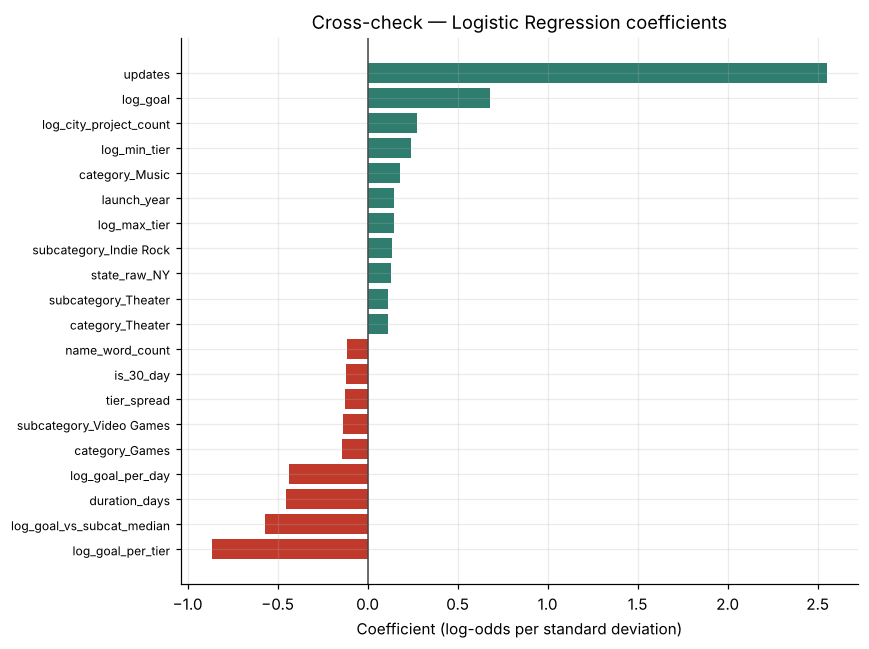

,feature,coefficient,direction
22,updates,2.553,raises success
12,log_goal_per_tier,-0.867,lowers success
0,log_goal,0.682,raises success
24,log_goal_vs_subcat_median,-0.569,lowers success
2,duration_days,-0.452,lowers success
4,log_goal_per_day,-0.435,lowers success
23,log_city_project_count,0.276,raises success
7,log_min_tier,0.242,raises success
33,category_Music,0.179,raises success
13,launch_year,0.148,raises success


In [53]:
coefs = pd.DataFrame({"feature": X_train.columns, "coefficient": lr.named_steps["clf"].coef_[0]})
coefs["abs"] = coefs["coefficient"].abs()
coefs["direction"] = np.where(coefs["coefficient"] > 0, "raises success", "lowers success")
top_coefs = coefs.sort_values("abs", ascending=False).head(20)

t = top_coefs.sort_values("coefficient")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(range(len(t)), t["coefficient"], color=[CORAL if v < 0 else TEAL for v in t["coefficient"]])
ax.axvline(0, color="#444", lw=1)
ax.set_yticks(range(len(t))); ax.set_yticklabels(t["feature"], fontsize=8)
ax.set_xlabel("Coefficient (log-odds per standard deviation)")
ax.set_title("Cross-check — Logistic Regression coefficients")
plt.tight_layout(); plt.savefig(FIG / "m3_coefficients.png", dpi=130, bbox_inches="tight"); plt.show()
top_coefs[["feature", "coefficient", "direction"]].head(10).round(3)

**Both models put `updates` far ahead of everything else.** Shuffling it
drops the final model's ROC-AUC by about 0.25; the next input, goal per reward
tier, drops it by about 0.02. Logistic Regression's largest coefficient is
also `updates` (about 2.6 per standard deviation, three times the next).

Below `updates` the two families agree with the launch-time analysis: the
**goal relative to the reward structure** (`log_goal_per_tier`), the **goal**
itself, **category**, the **entry price relative to the goal**, the
**creator's city size** and **campaign length**. The goal-derived features are
collinear, so individual Logistic Regression coefficients should be read as a
group (here `log_goal` is positive while `log_goal_per_tier` and
`log_goal_vs_subcat_median` are negative, which together say "a bigger ask
hurts").

Because `updates` dominates, the number of reward tiers matters much less to
this model than it did to the launch-time model (it ranks 12th here). The
Milestone 4 levers are estimated by the Logistic Regression advisor, which
still responds to them.

### 10.4 Where the final model goes wrong

- **False positive** — a creator is told the odds are good, and the campaign fails
- **False negative** — a creator is discouraged from a campaign that would have succeeded

In [54]:
confusion_frame(final_model, X_test, y_test)

,predicted: failed,predicted: successful
actual: failed,2701,774
actual: successful,642,3559


In [55]:
describe_errors(final_model, X_test, y_test, test).round(2)

,n,median_goal,median_duration,pct
error_type,,,,
true positive,3559,3000.0,30.63,46.4
true negative,2701,5700.0,36.96,35.2
"false positive (told to launch, would fail)",774,3000.0,31.00,10.1
"false negative (discouraged, would succeed)",642,3000.0,32.64,8.4


The two kinds of error are now close in size (10.1% false positives, 8.4%
false negatives). True negatives have the largest median goal ($5,700 against
$3,000 elsewhere), so goal size still separates the clear failures. Milestone 4
reports the held-out success rate next to every probability, so a single
number is never taken on trust.

### 10.5 Selecting the final model

First the final model's own before-and-after: the same tuned, calibrated
Random Forest fitted on each feature set.

In [56]:
fa_rows = []
for split_name, (tr, te) in SPLITS.items():
    for fs in FEATURE_SETS:
        X_a, y_a, X_b, y_b = model_matrices(tr, te, fs)
        m = make_final_model().fit(X_a, y_a)
        fa_rows.append(evaluate(m, X_b, y_b, label=FINAL_MODEL_NAME, feature_set=fs, split=split_name))
final_ab = pd.concat(fa_rows, ignore_index=True)
view = final_ab.set_index(["split", "feature_set"])[METRICS].unstack("feature_set")
for metric in METRICS:
    view[(metric, "change")] = view[(metric, "with_updates")] - view[(metric, "launch_only")]
view = view.sort_index(axis=1)
view.round(4)

accuracy                               f1                          precision                           recall                          roc_auc                         
feature_set     change launch_only with_updates  change launch_only with_updates    change launch_only with_updates  change launch_only with_updates  change launch_only with_updates
split                                                                                                                                                                                
chronological   0.0865      0.7183       0.8048  0.0594      0.7553       0.8147    0.1222      0.7056       0.8278 -0.0105      0.8125       0.8020  0.0990      0.7884       0.8874
random          0.1020      0.7135       0.8155  0.0781      0.7560       0.8341    0.1133      0.7080       0.8214  0.0362      0.8110       0.8472  0.1223      0.7753       0.8976

In [57]:
def row(df, name):
    return df[df.model == name].iloc[0]

fm, lrr = row(finalists, FINAL_MODEL_NAME), row(finalists, "Logistic Regression (tuned)")
fmc, lrc = row(chrono, FINAL_MODEL_NAME), row(chrono, "Logistic Regression (tuned)")
scorecard = pd.DataFrame([
    ("Accuracy (random split)", fm.accuracy, lrr.accuracy),
    ("Precision", fm.precision, lrr.precision),
    ("Recall", fm.recall, lrr.recall),
    ("F1", fm.f1, lrr.f1),
    ("ROC-AUC", fm.roc_auc, lrr.roc_auc),
    ("Accuracy (later campaigns)", fmc.accuracy, lrc.accuracy),
    ("ROC-AUC (later campaigns)", fmc.roc_auc, lrc.roc_auc),
    ("Largest calibration gap (pts)", worst["Random Forest (isotonic, final)"], worst["Logistic Regression"]),
], columns=["criterion", "Random Forest (final)", "Logistic Regression"])
lower_better = scorecard["criterion"].str.contains("calibration")
rf_wins = np.where(lower_better, scorecard.iloc[:, 1] < scorecard.iloc[:, 2],
                   scorecard.iloc[:, 1] > scorecard.iloc[:, 2])
scorecard["better"] = np.where(rf_wins, "Random Forest", "Logistic Regression")
scorecard["margin"] = (scorecard.iloc[:, 1] - scorecard.iloc[:, 2]).abs()
scorecard.round(4)

,criterion,Random Forest (final),Logistic Regression,better,margin
0,Accuracy (random split),0.8155,0.8158,Logistic Regression,0.0003
1,Precision,0.8214,0.8254,Logistic Regression,0.0040
2,Recall,0.8472,0.8415,Random Forest,0.0057
3,F1,0.8341,0.8333,Random Forest,0.0007
4,ROC-AUC,0.8976,0.8936,Random Forest,0.0039
5,Accuracy (later campaigns),0.8048,0.7991,Random Forest,0.0057
6,ROC-AUC (later campaigns),0.8874,0.8807,Random Forest,0.0067
7,Largest calibration gap (pts),4.0915,4.7437,Random Forest,0.6522


**Why the Random Forest is the final model**

1. **It wins six of the eight criteria in the scorecard**: recall, F1,
   ROC-AUC, accuracy and ROC-AUC on later campaigns, and calibration.
   Logistic Regression is ahead on accuracy (by 0.03 points) and precision.
   **The margins are small** — under one point of accuracy everywhere — and
   the scorecard shows every one.
2. **It holds up on later campaigns** (80.5% against Logistic Regression's
   79.9%), so the random split is not flattering it.
3. **Its probabilities are the best calibrated** after isotonic calibration
   (worst decile 4.1 points off, against 4.7 for Logistic Regression).
4. **It captures interactions without being told**, such as a large goal
   hurting more when there are few reward tiers.
5. **Interpretability is not lost**: permutation importance (§10.3) explains
   it, and Logistic Regression stays in the project as the *advisor* for
   what-if estimates.

**What `updates` did for this model** (the table above): accuracy 71.4% →
81.6% on the random split and 71.8% → 80.5% on later campaigns; ROC-AUC
0.775 → 0.898.

**What it is not:** a pure launch-day model. The 81.6% uses each campaign's
final update count. Before launch only a plan exists.

**An honest alternative.** Logistic Regression with `log(updates)` scored
82.3% in Task 9, about 0.7 points ahead. The team kept the Random Forest for
the reasons above; the alternative is recorded in Task 9 and the README.

### 10.6 Model card

In [58]:
def pick(df, split, fs, metric):
    return round(float(df[(df.split == split) & (df.feature_set == fs)][metric].iloc[0]), 4)

card = {
    "model": FINAL_MODEL_NAME,
    "algorithm": "RandomForestClassifier wrapped in CalibratedClassifierCV(method='isotonic', cv=3)",
    "hyperparameters": FINAL_RF_PARAMS,
    "feature_set": FINAL_FEATURE_SET,
    "task": "Binary classification — will a Kickstarter campaign reach its goal?",
    "prediction_point": ("Campaign launch plus the number of updates posted during the campaign. "
                         "Trained and tested on each campaign's final update count; before launch "
                         "the prototype uses the creator's planned number of updates."),
    "training_rows": int(len(X_train)), "test_rows": int(len(X_test)),
    "n_features": int(X_train.shape[1]),
    "majority_class_floor": round(FLOOR_ACC, 4),
    "accuracy": round(float(fm.accuracy), 4), "precision": round(float(fm.precision), 4),
    "recall": round(float(fm.recall), 4), "f1": round(float(fm.f1), 4),
    "roc_auc": round(float(fm.roc_auc), 4),
    "chronological_accuracy": round(float(fmc.accuracy), 4),
    "chronological_roc_auc": round(float(fmc.roc_auc), 4),
    "largest_calibration_gap_pts": round(float(worst["Random Forest (isotonic, final)"]), 1),
    "same_model_launch_only": {m: pick(final_ab, "random", "launch_only", m) for m in METRICS},
    "same_model_launch_only_chronological_accuracy": pick(final_ab, "chronological", "launch_only", "accuracy"),
    "top_features": fimp["label"].head(5).tolist(),
    "excluded_for_leakage": ["pledged", "funded_percentage", "backers", "comments"],
    "advisor_model_for_what_if": "Logistic Regression (tuned) — see src/recommend.py",
    "known_limitations": [
        "Uses `updates`, counted at the end of each campaign: before launch only a planned number exists",
        "Part of the `updates` signal is reverse causation (campaigns doing well post more)",
        "Trained on 2009-2012 data; not validated for present-day Kickstarter",
        "US campaigns only",
        "No campaign text, video, image or creator-history signal available",
    ],
}
(REPORTS / "m3_model_card.json").write_text(json.dumps(card, indent=2))
pd.concat([finalists, chrono, final_ab], ignore_index=True).to_csv(
    REPORTS / "m3_task10_finalists.csv", index=False)
print(json.dumps(card, indent=2))

{
  "model": "Random Forest (tuned + calibrated)",
  "algorithm": "RandomForestClassifier wrapped in CalibratedClassifierCV(method='isotonic', cv=3)",
  "hyperparameters": {
    "n_estimators": 400,
    "min_samples_leaf": 3,
    "max_features": 0.3,
    "max_depth": 12
  },
  "feature_set": "with_updates",
  "task": "Binary classification \u2014 will a Kickstarter campaign reach its goal?",
  "prediction_point": "Campaign launch plus the number of updates posted during the campaign. Trained and tested on each campaign's final update count; before launch the prototype uses the creator's planned number of updates.",
  "training_rows": 30702,
  "test_rows": 7676,
  "n_features": 138,
  "majority_class_floor": 0.5473,
  "accuracy": 0.8155,
  "precision": 0.8214,
  "recall": 0.8472,
  "f1": 0.8341,
  "roc_auc": 0.8976,
  "chronological_accuracy": 0.8048,
  "chronological_roc_auc": 0.8874,
  "largest_calibration_gap_pts": 4.1,
  "same_model_launch_only": {
    "accuracy": 0.7135,
    "preci

### Task 10 — Summary and Milestone 3 close-out

#### What was produced

| Artefact | File |
|---|---|
| Leakage register | `reports/m3_leakage_register.csv` |
| Split summary | `reports/m3_split_summary.csv` |
| All Task 7 model runs (3 models + tuned LR, 2 feature sets, 2 splits) | `reports/m3_task7_model_results.csv` |
| Logistic Regression coefficients | `reports/m3_lr_coefficients.csv` |
| Comparison table | `reports/m3_task8_comparison.csv` |
| Before/after `updates`, every model | `reports/m3_updates_effect.csv` |
| Tuning, class balancing and `log(updates)` results | `reports/m3_task9_tuned_results.csv` |
| Tuned configuration | `reports/m3_tuned_config.json` |
| Final model's feature importance | `reports/m3_final_feature_importance.csv` |
| Finalists, both splits, both feature sets | `reports/m3_task10_finalists.csv` |
| Model card | `reports/m3_model_card.json` |

#### Limitations

1. **`updates` is counted when a campaign ends.** The 81.6% is measured with
   the actual final count; before launch the prototype has only the
   creator's plan, so real pre-launch accuracy is lower by an amount this data
   cannot measure. Without `updates` the same model scores 71.4%.
2. **Part of the `updates` signal is reverse causation.** Campaigns that are
   succeeding attract more updates, so "post more updates" is not supported
   advice.
3. **The two best models are level.** The Random Forest's lead is under one
   point on every metric, and Logistic Regression is ahead on accuracy.
4. **Platform drift and scope.** Trained on 2009–2012 US Kickstarter only.
5. **No campaign text, video, image count, creator history or social
   following** is in the scrape.

#### Handoff to Milestone 4

`src/modeling.make_final_model()` builds this exact model, and
`src/recommend.py` uses it to score campaigns. The prototype asks the creator
for their **planned** number of updates and never recommends changing it.
The changeable features — goal, duration, reward tiers — are what the
recommendations target; category and location inform the prediction but
cannot inform advice.